# Phase 3–6 — Technical Indicators, Feature Engineering, Target and Train/Test Split

This notebook builds the modelling matrix. All code lives in `src/indicators.py`,
`src/features.py` so the Streamlit app can reproduce it exactly.

**Leakage rule applied throughout:** a row dated *t* may only use information from *t* and
earlier. Every indicator is a backward-looking rolling statistic, the target is created by
shifting the close **forward** (and is never used as a feature), and the split is
chronological.

In [1]:
from pathlib import Path
import sys

# make the project root importable no matter where the notebook is started from
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 60)

from src.data_loader import prepare
from src.indicators import add_indicators, indicator_descriptions, INDICATOR_COLS
from src.features import (BASE_FEATURES, TARGET, add_target, engineer_features,
                          drop_incomplete, make_split)

raw = prepare()
df = add_indicators(raw)
df.tail(3)

Loaded cached data <- C:\Users\KIIT\Documents\StockMarketAnalyzer\stock_market_ai\data\stock_data.csv

--- Phase 1 cleaning report ---
  missing_before: {}
  duplicate_rows: 0
  missing_after: {}
  rows: 6480
  symbols: ['RELIANCE.NS', 'TCS.NS', '^NSEI']
  date_min: 2018-01-01
  date_max: 2026-09-28


,Date,Close,High,Low,Open,Volume,Symbol,Name,Daily_Return,MA_5,MA_20,RSI,MACD,MACD_Signal,MACD_Hist,Volatility_10,Volume_Change
6477,2026-09-24,"23,063.10","23,281.95","23,046.15","23,221.80","271,700.00",^NSEI,NIFTY 50,-0.02,"23,319.92","23,600.82",30.97,-240.88,-222.19,-18.69,0.12,0.14
6478,2026-09-25,"23,140.50","23,162.70","23,020.95","23,035.00","242,700.00",^NSEI,NIFTY 50,0.00,"23,278.74","23,553.30",34.23,-244.15,-226.58,-17.56,0.12,-0.11
6479,2026-09-28,"22,780.25","23,080.25","22,762.20","23,064.90","261,500.00",^NSEI,NIFTY 50,-0.02,"23,151.93","23,483.53",27.69,-272.66,-235.80,-36.86,0.14,0.08


## Phase 3 — Technical indicators and what each one means

`Daily_Return`, `MA_5`, `MA_20`, `RSI`, `MACD`, `Volatility_10` and `Volume_Change` are
computed **per instrument** with strictly backward-looking windows.

In [2]:
indicator_descriptions()

,Indicator,Calculation,Why it helps ML
0,MA_5,5-day simple moving average of close,Short-term trend level
1,MA_20,20-day simple moving average of close,Medium-term trend level
2,Daily_Return,(Close[t] - Close[t-1]) / Close[t-1],One-day momentum
3,RSI,"100 - 100/(1 + avg_gain/avg_loss), 14 days",Overbought/oversold (0-100)
4,MACD,EMA12(Close) - EMA26(Close),Trend/momentum line
5,MACD_Signal,EMA9(MACD),MACD trigger line
6,MACD_Hist,MACD - MACD_Signal,Trend-shift histogram
7,Volatility_10,"std(ret,10) * sqrt(252)",Annualised 10-day risk
8,Volume_Change,(Vol[t] - Vol[t-1]) / Vol[t-1],Volume shock detector


In [3]:
sample = df[df["Symbol"] == "RELIANCE.NS"].tail(15)
sample[["Date", "Close"] + INDICATOR_COLS].round(3)

,Date,Close,MA_5,MA_20,RSI,MACD,MACD_Signal,MACD_Hist,Volatility_10,Volume_Change
2148,2026-09-08,"1,294.90","1,308.40","1,307.81",46.63,-0.78,-0.56,-0.22,0.21,-0.04
2149,2026-09-09,"1,279.00","1,301.58","1,305.31",42.36,-2.77,-1.00,-1.77,0.20,0.24
2150,2026-09-10,"1,274.00","1,295.88","1,303.16",41.08,-4.70,-1.74,-2.96,0.20,-0.23
2151,2026-09-11,"1,257.50","1,282.98","1,300.54",37.11,-7.47,-2.89,-4.58,0.20,-0.06
2152,2026-09-14,"1,257.50","1,272.58","1,297.61",37.11,-9.56,-4.22,-5.34,0.20,0.00
2153,2026-09-15,"1,235.30","1,260.66","1,293.28",32.24,-12.86,-5.95,-6.91,0.15,0.57
2154,2026-09-16,"1,240.00","1,252.86","1,289.72",34.21,-14.92,-7.74,-7.18,0.15,-0.27
2155,2026-09-17,"1,243.90","1,246.84","1,286.26",35.87,-16.05,-9.40,-6.65,0.16,-0.23
2156,2026-09-18,"1,226.40","1,240.62","1,281.78",31.97,-18.15,-11.15,-7.00,0.12,0.95
2157,2026-09-21,"1,247.40","1,238.60","1,278.66",40.36,-17.92,-12.51,-5.41,0.17,-0.34


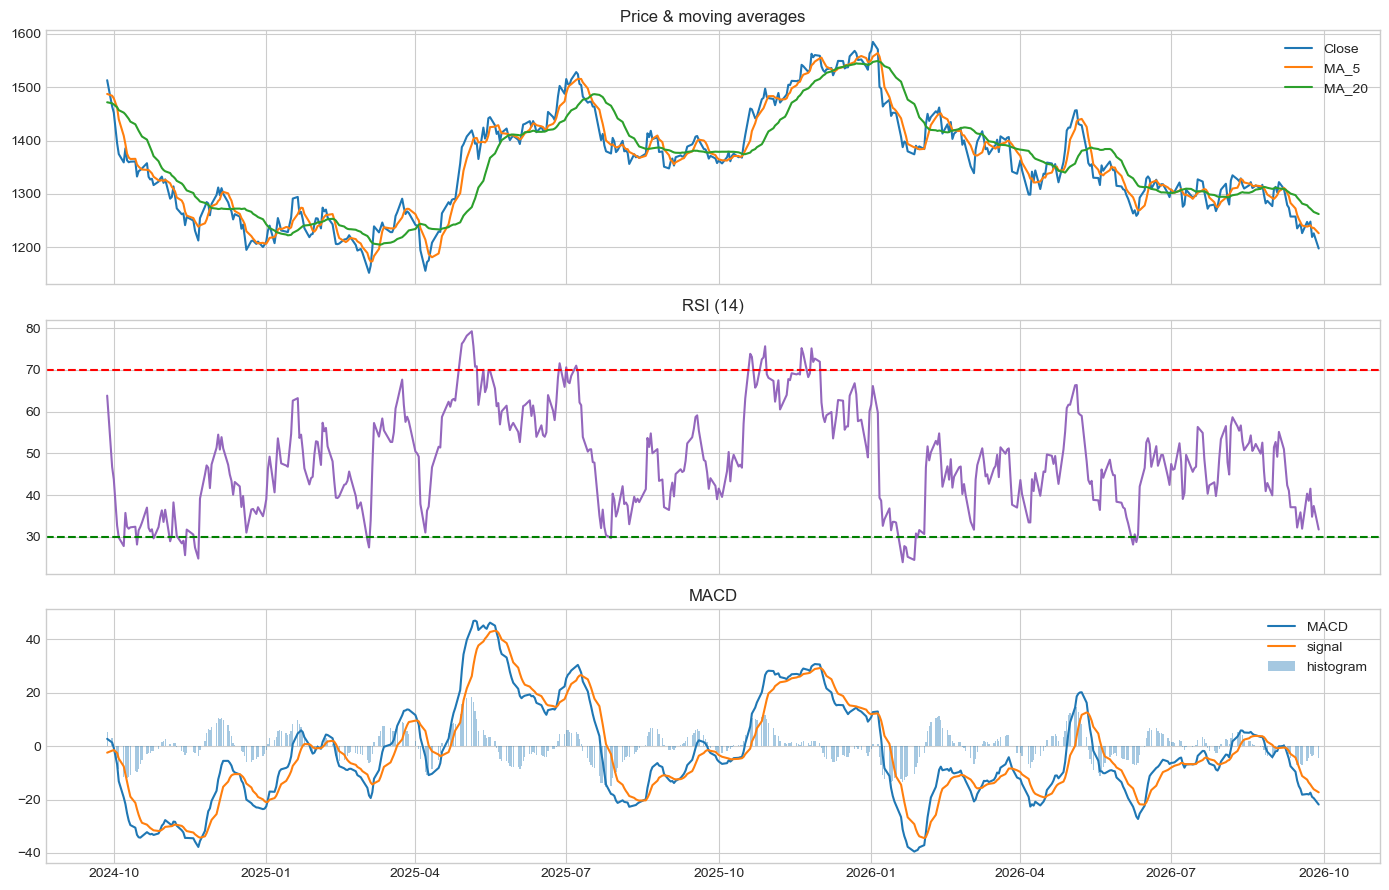

In [4]:
# visual sanity check of RSI and MACD on the last two years
part = df[df["Symbol"] == "RELIANCE.NS"].tail(500)
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(part["Date"], part["Close"], label="Close"); axes[0].plot(part["Date"], part["MA_5"], label="MA_5")
axes[0].plot(part["Date"], part["MA_20"], label="MA_20"); axes[0].legend(); axes[0].set_title("Price & moving averages")
axes[1].plot(part["Date"], part["RSI"], color="#9467bd"); axes[1].axhline(70, ls="--", c="r"); axes[1].axhline(30, ls="--", c="g")
axes[1].set_title("RSI (14)")
axes[2].plot(part["Date"], part["MACD"], label="MACD"); axes[2].plot(part["Date"], part["MACD_Signal"], label="signal")
axes[2].bar(part["Date"], part["MACD_Hist"], alpha=0.4, label="histogram"); axes[2].legend(); axes[2].set_title("MACD")
fig.tight_layout()

## Phase 4 — Feature engineering

Base set from the brief (`Open, High, Low, Close, Volume, Daily_Return, MA_5, MA_20, RSI,
MACD, Volatility_10, Volume_Change, Previous_Day_Return`) plus engineered extras:

| Feature | Idea |
|---|---|
| `Close_vs_MA5`, `Close_vs_MA20` | distance from the trend → normalises across instruments |
| `High_Low_Range`, `Close_Open_Chg` | intraday shape, scale free |
| `Return_Lag_2/3`, `Return_Mean_5` | short return history / momentum |
| `RSI_Distance` | RSI relative to its neutral 50 |
| `MACD_Hist` | trend-shift signal |
| `Volume_Z` | volume shock vs. its 60-day normal range |
| `DayOfWeek`, `Month` | calendar effects (stored as integers, tree models handle them) |

**A. Why is feature engineering required?** Raw OHLCV values are non-stationary and have
different scales per instrument; a model cannot learn "price went up" from an absolute
price. Ratios, differences and rolling statistics turn the raw series into stationary,
scale-free signals and expose the patterns (trend distance, momentum, volatility, volume
shock) the classifier can actually split on.

**B. Which features appear most useful?** The trend/momentum block (`Close_vs_MA20`,
`Return_Mean_5`, `MACD_Hist`, `RSI_Distance`) and the risk block (`Volatility_10`,
`High_Low_Range`); the notebook at the end of Phase 8 prints the model's own ranking.

**C. Any features that should be removed?** `Open/High/Low/Close` in raw form are almost
collinear with each other and dominate by scale — they add little after the ratio
features, and `DayOfWeek/Month` are weak, cyclic artefacts. They are kept because the
brief lists them, but the ablation in Phase 8 shows near-zero importance for the raw
price columns once the ratios exist.

In [5]:
df = engineer_features(df)
print(f"{len(BASE_FEATURES)} features:")
print(BASE_FEATURES)

# quick signal check: point-biserial correlation of each feature with the target
probe = add_target(df).dropna(subset=[TARGET])
corr = probe[BASE_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr.round(3).to_frame("corr with Next_Day_Direction")

25 features:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'MA_5', 'MA_20', 'RSI', 'MACD', 'Volatility_10', 'Volume_Change', 'Previous_Day_Return', 'Close_vs_MA5', 'Close_vs_MA20', 'High_Low_Range', 'Close_Open_Chg', 'Return_Lag_2', 'Return_Lag_3', 'Return_Mean_5', 'RSI_Distance', 'MACD_Hist', 'Volume_Z', 'DayOfWeek', 'Month']


,corr with Next_Day_Direction
Month,0.04
MACD,0.02
RSI_Distance,0.02
RSI,0.02
MA_5,0.01
MA_20,0.01
High,0.01
Volume_Change,0.01
Open,0.01
Close,0.01


## Phase 5 — Prediction target `Next_Day_Direction`

```
1 = next day's closing price > today's closing price
0 = next day's closing price <= today's closing price
```

The target is created *after* the features by shifting the close one day forward; the row
with an unknown future is dropped.

**A. Classification or regression?** **Classification** — the label is a discrete binary
outcome (UP/DOWN), not a continuous quantity.

**B. Why?** We are predicting a *category of movement*, not the future price itself.
Classification gives probabilities we can turn into a confidence score and lets us use
precision/recall/F1/confusion-matrix evaluation. (Predicting tomorrow's price and then
taking its sign would be regression followed by thresholding, which is harder to calibrate
and much more sensitive to outliers.)

In [6]:
df = add_target(df)
df = drop_incomplete(df)

today_tomorrow = (df[df["Symbol"] == "RELIANCE.NS"]
                  .assign(Tomorrow_Close=lambda d: d["Close"].shift(-1),
                          Target_raw=lambda d: (d["Close"].shift(-1) > d["Close"]).astype("Int64"))
                  .tail(6)[["Date", "Close", "Tomorrow_Close", "Target_raw"]])
display(today_tomorrow.round(2))

print("target distribution:")
display(df[TARGET].value_counts(normalize=True).round(4).to_frame("share"))

Feature matrix: 6480 rows -> 6420 usable rows (warm-up/target rows dropped: 60)


,Date,Close,Tomorrow_Close,Target_raw
2137,2026-09-18,"1,226.40","1,247.40",1
2138,2026-09-21,"1,247.40","1,240.40",0
2139,2026-09-22,"1,240.40","1,248.00",1
2140,2026-09-23,"1,248.00","1,219.20",0
2141,2026-09-24,"1,219.20","1,226.00",1
2142,2026-09-25,"1,226.00",NaN,0


target distribution:


,share
Next_Day_Direction,
1,0.52
0,0.48


## Phase 6 — Train / test preparation

* **No shuffling.** The first **80 %** of each instrument's history trains the model, the
  last **20 %** tests it. The scaler is fit on the training window only.

**A. Why not shuffle time-series data?** Shuffling mixes 2019 rows into the test set and
2025 rows into the training set. The model would then be scored on periods it has already
"seen" through their neighbours, and it would learn patterns that had not happened yet at
training time — the score becomes a measure of interpolation, not forecasting.

**B. What is look-ahead bias?** Using information from the future to make a decision that
supposedly had to be made in the past (today's close, tomorrow's news, a scaler fitted on
2025 data). It silently inflates accuracy and destroys any real trading value.

**C. How could future information leak into training?** Five ways, all covered in
Phase 14: the target itself sitting among the features, tomorrow's volume, news published
after the prediction date, random mixing of future and past rows, and scaling/normalising
the whole dataset before the split.

In [7]:
full = df.copy()
train, test = make_split(full, train_ratio=0.8)

check = pd.DataFrame({
    "rows": [len(train), len(test)],
    "start": [train["Date"].min().date(), test["Date"].min().date()],
    "end": [train["Date"].max().date(), test["Date"].max().date()],
    "up share": [train[TARGET].mean(), test[TARGET].mean()],
}, index=["train (first 80%)", "test (last 20%)"])
display(check.round(3))

# --- structural leakage assertions -------------------------------------------------
for sym, part in full.groupby("Symbol"):
    part = part.sort_values("Date")
    cut = int(len(part) * 0.8)
    assert part["Date"].iloc[:cut].max() < part["Date"].iloc[cut:].min(), "windows overlap"
    assert list(part["Date"]) == sorted(part["Date"]), "not chronological"
assert TARGET not in BASE_FEATURES, "target leaked into features"
assert not full[BASE_FEATURES].isna().any().any(), "NaNs left in the feature matrix"
print("OK: chronological, non-overlapping windows; target excluded from the features.")

,rows,start,end,up share
train (first 80%),5138,2018-01-29,2025-01-08,0.53
test (last 20%),1282,2025-01-09,2026-09-25,0.47


OK: chronological, non-overlapping windows; target excluded from the features.


In [8]:
# look-ahead test: rebuilding the features on data truncated at a date must give the
# exact same values for every row on or before that date.
cut = pd.Timestamp("2023-06-30")
truncated = engineer_features(add_indicators(raw[raw["Date"] <= cut]))
ref = full[full["Date"] <= cut].sort_values(["Symbol", "Date"]).reset_index(drop=True)
truncated = truncated.dropna(subset=BASE_FEATURES).sort_values(["Symbol", "Date"]).reset_index(drop=True)
diff = (ref[BASE_FEATURES] - truncated[BASE_FEATURES]).abs().max().max()
print(f"max absolute difference on rows <= {cut.date()}: {diff:.3e}")
assert diff < 1e-9, "feature values changed when future rows were removed"
print("OK: no feature depends on the future.")

max absolute difference on rows <= 2023-06-30: 0.000e+00
OK: no feature depends on the future.
